### IT5092 – Neuroscience & Neurocomputing
### Lab 01 (Week 1): EEG Rhythms & Behavioural State Inference (Guided)

**Type:** Individual Lab  
**Duration:** 2 hours
**Submission:** One `.ipynb` file 

---
#### Learning Outcomes
By the end of this lab, you will be able to:
1. Load and inspect a real EEG dataset programmatically
2. Perform basic EEG preprocessing (channel selection, filtering, referencing)
3. Compute Power Spectral Density (PSD) and band power features (delta/theta/alpha/beta/gamma)
4. Test a neuroscience hypothesis computationally by comparing alpha-band activity across different brain states (e.g., eyes open vs eyes closed).
5. Write a short scientific-style interpretation connecting rhythms ↔ brain state ↔ behaviour


Raw EEG signals (µV, time domain)
        ->
Preprocessing (filtering, referencing)
        ->
Frequency analysis (PSD)
        ->
Feature extraction (band power)
        ->
Interpretation (brain state / behavior)


#### 1) Install libraries

In [1]:
# Installs into THIS kernel (not your terminal python).
# Run once, then RESTART THE KERNEL before running the rest.
%pip install -q mne numpy scipy matplotlib



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [37]:
import mne
import numpy as np
import matplotlib.pyplot as plt

mne.set_log_level('WARNING')

print("MNE version:", mne.__version__)
print("NumPy version:", np.__version__)


MNE version: 1.12.1
NumPy version: 2.5.1


In [38]:
import os

os.environ["MNE_DATA"] = "/Users/nisalgangana/Documents/SLIIT/Y1S2/NN/week-1/eeg-motor-movementimagery-dataset-1.0.0"

base = os.environ["MNE_DATA"]
print("MNE_DATA =", base)
print("Path exists:", os.path.isdir(base))

# MNE looks for this exact layout inside MNE_DATA:
expected = os.path.join(base, "MNE-eegbci-data", "files", "eegmmidb", "1.0.0", "S001", "S001R01.edf")
print("Run 1 found locally:", os.path.exists(expected))
if not os.path.exists(expected):
    print("-> Not in expected layout. Top-level contents:", sorted(os.listdir(base))[:8])
    print("-> MNE will re-download unless the folder structure is fixed.")


MNE_DATA = /Users/nisalgangana/Documents/SLIIT/Y1S2/NN/week-1/eeg-motor-movementimagery-dataset-1.0.0
Path exists: True
Run 1 found locally: True


In [39]:
# Download one subject, one run (very small)
subject = 1
runs = [1]   # baseline (eyes open)

raw_files = mne.datasets.eegbci.load_data(subject, runs)
raw = mne.io.read_raw_edf(raw_files[0], preload=True)

raw

<RawEDF | S001R01.edf, 64 x 9760 (61.0 s), ~4.8 MiB, data loaded>

#### Task B1:
Load baseline run 2 (eyes closed) for comparison

In [21]:
# ===== Task B1: Load baseline Run 2 (eyes closed) for comparison =====

subject_b1 = 1
runs_b1 = [2]            # Run 2 = baseline, EYES CLOSED

raw_files_run2 = mne.datasets.eegbci.load_data(subject_b1, runs_b1)
raw_run2 = mne.io.read_raw_edf(raw_files_run2[0], preload=True)

print("Run 1 (eyes open)  -> sfreq:", raw.info["sfreq"],
      "| channels:", len(raw.ch_names),
      "| duration: %.1f s" % raw.times[-1])
print("Run 2 (eyes closed)-> sfreq:", raw_run2.info["sfreq"],
      "| channels:", len(raw_run2.ch_names),
      "| duration: %.1f s" % raw_run2.times[-1])

raw_run2

Run 1 (eyes open)  -> sfreq: 160.0 | channels: 64 | duration: 61.0 s
Run 2 (eyes closed)-> sfreq: 160.0 | channels: 64 | duration: 61.0 s


<RawEDF | S001R02.edf, 64 x 9760 (61.0 s), ~4.8 MiB, data loaded>

#### 2) Load EEG Dataset (MNE sample)
This uses an EEG dataset shipped with MNE (it may download the first time).

160.0
64


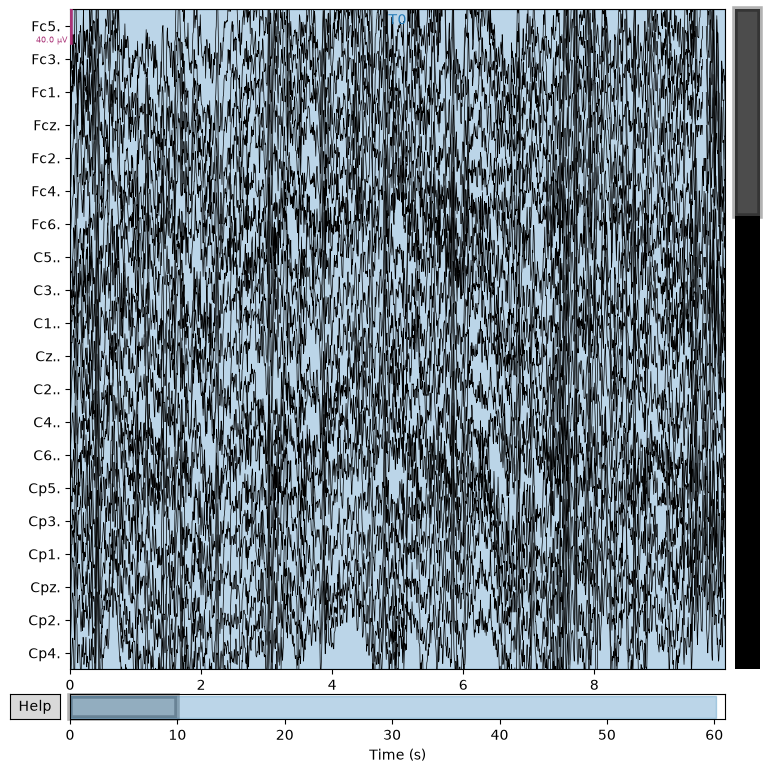

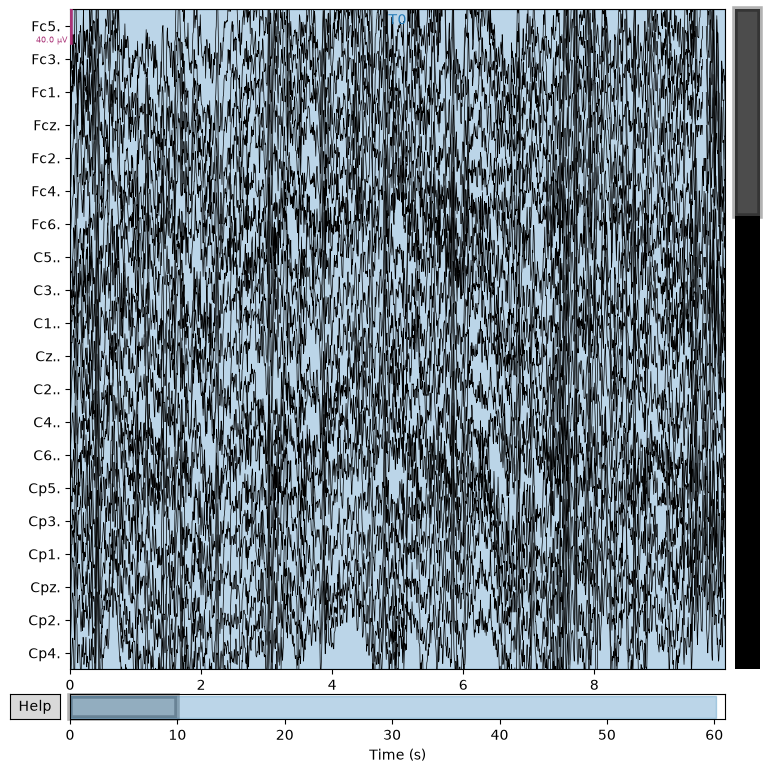

In [22]:
print(raw.info["sfreq"])      # sampling rate
print(len(raw.ch_names))      # number of channels
raw.plot(duration=10, n_channels=20)

#### Feature Types
1) Power at each frequency - EEG voltage
2) Power Spectral Density (PSD) - Power at each frequency
3) Band Power Features (Alpha,Delta,Thete,Beta,Gamma)


#### 3) Pick EEG + quick metadata
We keep EEG and EOG (eye channel) for inspection, then exclude EOG during rhythm computation.


In [23]:

raw_eeg = raw.copy().pick_types(meg=False, eeg=True, eog=True, stim=False, exclude='bads')

sfreq = raw_eeg.info['sfreq']
duration = raw_eeg.times[-1]
n_chan = len(raw_eeg.ch_names)

print(f'Sampling rate: {sfreq} Hz')
print(f'Duration: {duration:.1f} s')
print(f'Channels kept: {n_chan}')
print('First 12 channels:', raw_eeg.ch_names[:12])


Sampling rate: 160.0 Hz
Duration: 61.0 s
Channels kept: 64
First 12 channels: ['Fc5.', 'Fc3.', 'Fc1.', 'Fcz.', 'Fc2.', 'Fc4.', 'Fc6.', 'C5..', 'C3..', 'C1..', 'Cz..', 'C2..']


### Task 2: Student write-up (3–5 lines)
- What is EEG measuring (single neuron vs population)?
- Mention **two** brain rhythms and what behavioural state they relate to.


### Task 2 — Answers (Q1 & Q2)

**1. What is EEG measuring (single neuron vs population)?**
EEG measures the synchronized electrical activity of a large population of neurons, not a single neuron.

**2. Two brain rhythms and the behavioural states they relate to**
- **Alpha rhythm** relates to a relaxed, awake state (especially with eyes closed).
- **Beta rhythm** relates to an active, alert, and focused state.

#### 4) Visualize raw EEG (time domain)
Inspect ~10 seconds and identify artifacts.


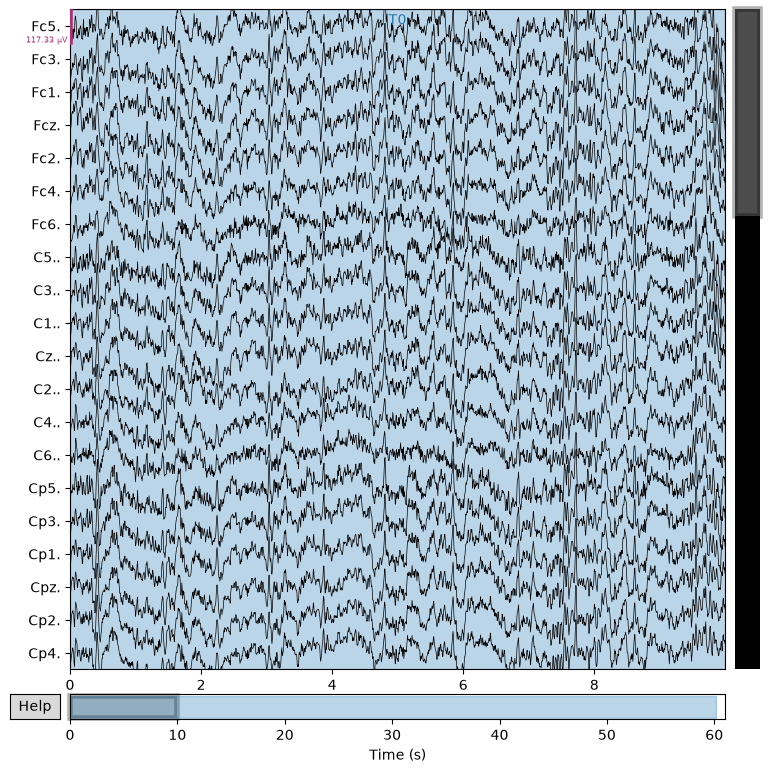

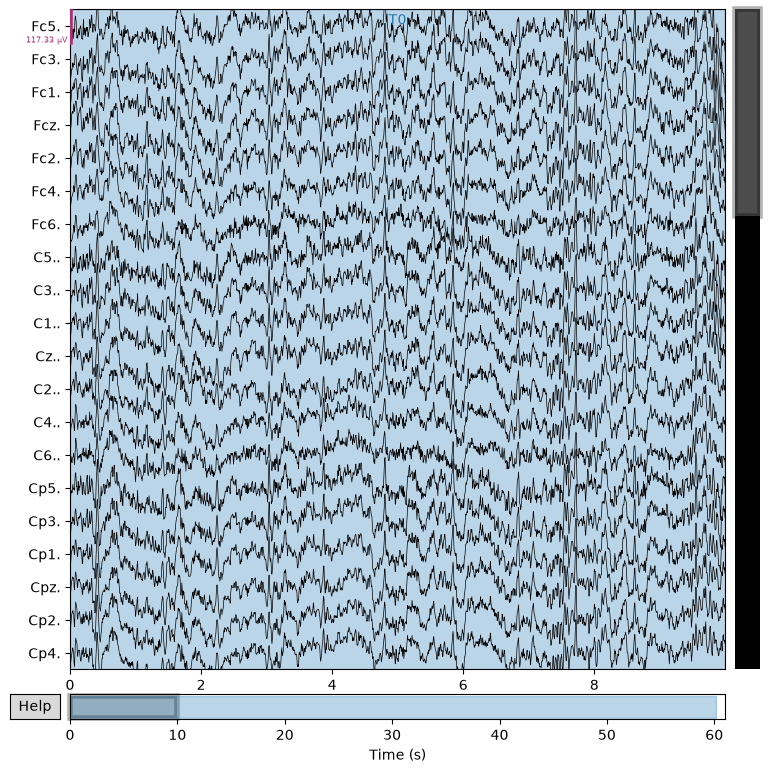

In [24]:
raw_eeg.plot(duration=10, n_channels=20, scalings='auto')


### Task 2: Student write-up
- Identify **two** artifacts you can see (e.g., blink, slow drift, muscle).


### Task 2 — Answers (Q3)

**3. Two artifacts visible in the raw trace**
- **Eye blink artifacts** (caused by eye movements) — large, slow deflections strongest in the frontal channels.
- **Muscle artifacts** (caused by jaw or facial muscle movements) — bursts of fast, high-frequency activity.

#### 5) Preprocessing baseline
We apply:
- Average reference
- Band-pass filter 1–45 Hz
- 50 Hz notch filter (mains)


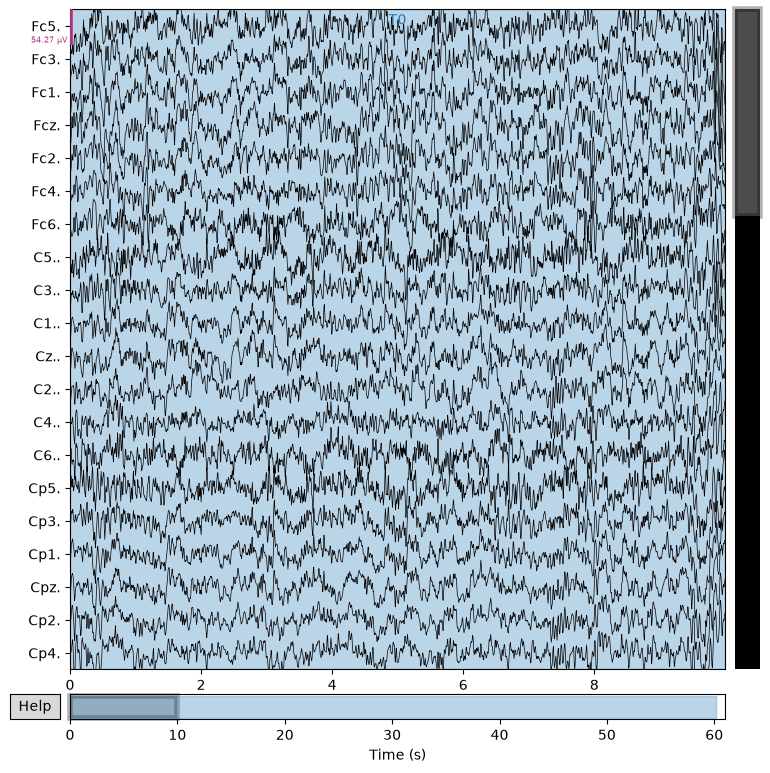

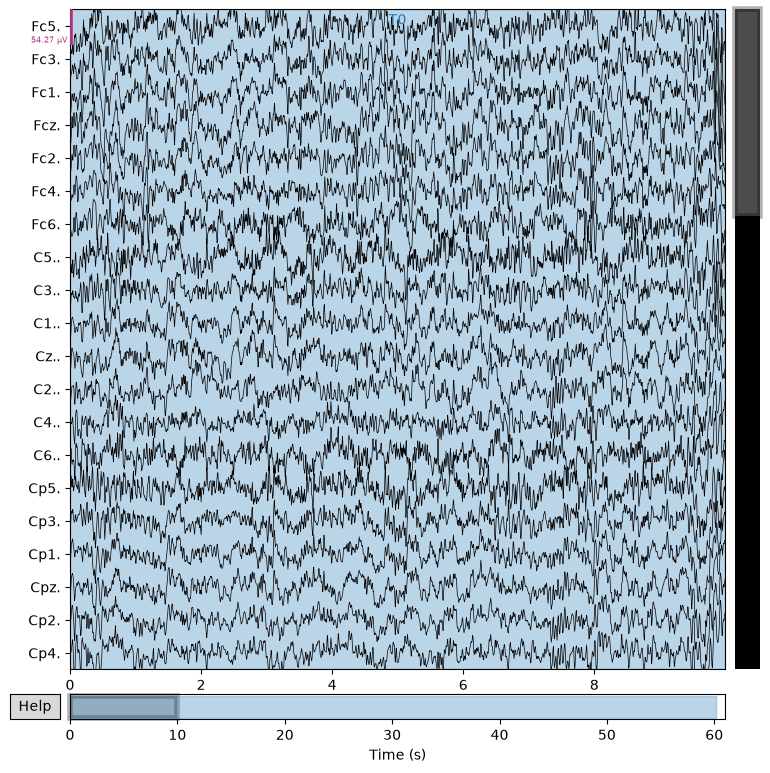

In [25]:
raw_prep = raw_eeg.copy()

# Average reference
raw_prep.set_eeg_reference('average')

# Band-pass filter for rhythms
raw_prep.filter(l_freq=1.0, h_freq=45.0)

# 50 Hz notch (mains interference)
raw_prep.notch_filter(freqs=[50.0])

raw_prep.plot(duration=10, n_channels=20, scalings='auto')


### Task 2: Student write-up (Short answers)
1. Why is **1–45 Hz** a reasonable range for rhythm analysis in this introductory lab?
2. What does the **50 Hz notch** filter remove, and why is it relevant in Sri Lanka?


### Task 2 — Answers (Q4 & Q5)

**4. Why is 1–45 Hz a reasonable range for rhythm analysis in this introductory lab?**
Most relevant brain rhythms fall within the 1–45 Hz range. Frequencies above 45 Hz are often dominated by muscle artifacts and power-line noise, so excluding them provides a cleaner signal.

**5. What does the 50 Hz notch filter remove, and why is it relevant in Sri Lanka?**
It removes power-line interference (electrical noise). It is highly relevant because the standard AC power grid in Sri Lanka operates at 50 Hz.

#### 6) Power Spectral Density (PSD)
Compute PSD using Welch and plot mean PSD across channels.


In [26]:
# Keep only EEG channels for rhythm analysis
raw_psd = raw_prep.copy().pick_types(eeg=True, eog=False)

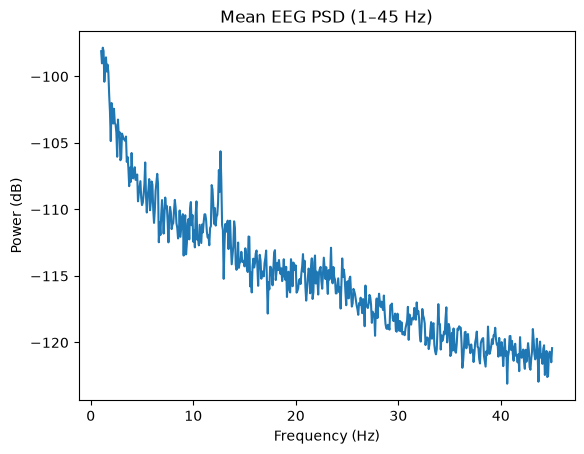

In [27]:
# Compute PSD using the modern MNE API

psd = raw_psd.compute_psd(
    method="welch",
    fmin=1,
    fmax=45,
    n_fft=2048
)

psds = psd.get_data()      # (n_channels, n_freqs)
freqs = psd.freqs

"""What this line does

Converts the power spectral density (PSD) values from a linear scale to a logarithmic (decibel) scale

Formula used: Power (dB) = 10 * log10(Power)"""
psds_db = 10 * np.log10(psds)

plt.figure()
plt.plot(freqs, psds_db.mean(axis=0))
plt.title("Mean EEG PSD (1–45 Hz)")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (dB)")
plt.show()

### Task B2 (small code change + explanation)
1. Plot PSD for **one chosen channel** (pick a channel name you see in `raw_psd.ch_names`).
2. Write 2–3 lines: how does PSD help you identify rhythms?


Available channels (first 15): ['Fc5.', 'Fc3.', 'Fc1.', 'Fcz.', 'Fc2.', 'Fc4.', 'Fc6.', 'C5..', 'C3..', 'C1..', 'Cz..', 'C2..', 'C4..', 'C6..', 'Cp5.']
Chosen channel: O1..


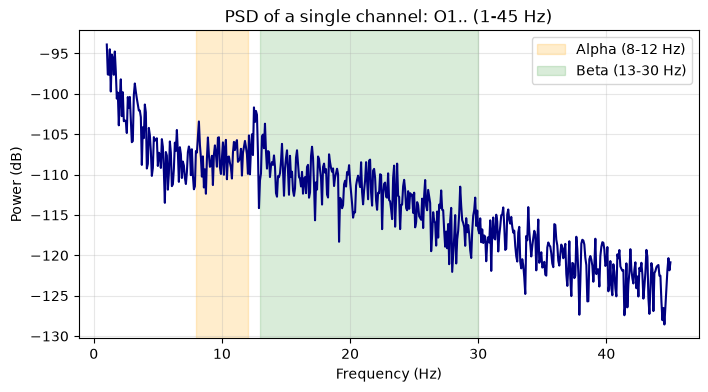

Peak frequency for O1..: 1.02 Hz


In [28]:
# ===== Task B2: Plot the PSD for ONE chosen channel =====

print("Available channels (first 15):", raw_psd.ch_names[:15])

# EEGBCI channel names carry trailing dots (e.g. 'Oz..', 'C3..'),
# so we match on the cleaned name and fall back to the first channel.
preferred = "O1"      # occipital -> strongest alpha; try "C3" or "Cz" as well
ch_name = next(
    (ch for ch in raw_psd.ch_names
     if ch.replace(".", "").strip().lower() == preferred.lower()),
    raw_psd.ch_names[0]
)
ch_idx = raw_psd.ch_names.index(ch_name)
print("Chosen channel:", ch_name)

# psds / freqs / psds_db were computed in the PSD cell above
plt.figure(figsize=(8, 4))
plt.plot(freqs, psds_db[ch_idx], color="navy")
plt.axvspan(8, 12, color="orange", alpha=0.20, label="Alpha (8-12 Hz)")
plt.axvspan(13, 30, color="green", alpha=0.15, label="Beta (13-30 Hz)")
plt.title(f"PSD of a single channel: {ch_name} (1-45 Hz)")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (dB)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Where is this channel's strongest rhythm?
peak_freq = freqs[np.argmax(psds_db[ch_idx])]
print(f"Peak frequency for {ch_name}: {peak_freq:.2f} Hz")

### Task B2 — How does PSD help identify rhythms?

The PSD converts the EEG signal from the time domain into the frequency domain, showing how the total power of the signal is distributed across frequencies. Instead of reading tangled voltage traces, we can directly see **peaks** in the spectrum, and a peak sitting inside a known band tells us which rhythm dominates — for example, a clear bump around 8–12 Hz indicates strong **alpha** activity. This makes the PSD the bridge between the raw signal and interpretable numerical features (band powers) that describe the brain state.

#### 7) Band power features
We compute mean power in standard rhythm bands.


In [29]:
bands = {
    'delta': (1, 4),
    'theta': (4, 8),
    'alpha': (8, 12),
    'beta':  (13, 30),
    'gamma': (30, 45)
}

def bandpower_mean(psds, freqs, fmin, fmax):
    idx = (freqs >= fmin) & (freqs <= fmax)
    return psds[:, idx].mean(axis=1)


In [30]:
band_powers = {b: bandpower_mean(psds, freqs, lo, hi) for b, (lo, hi) in bands.items()}

alpha = band_powers['alpha']
top_idx = np.argsort(alpha)[-5:][::-1]

print('Top 5 channels by alpha band power:')
for i in top_idx:
    print(f"{raw_psd.ch_names[i]} : {alpha[i]:.3e}")


Top 5 channels by alpha band power:
O2.. : 1.928e-11
O1.. : 1.804e-11
Iz.. : 1.731e-11
Oz.. : 1.680e-11
Po8. : 1.649e-11


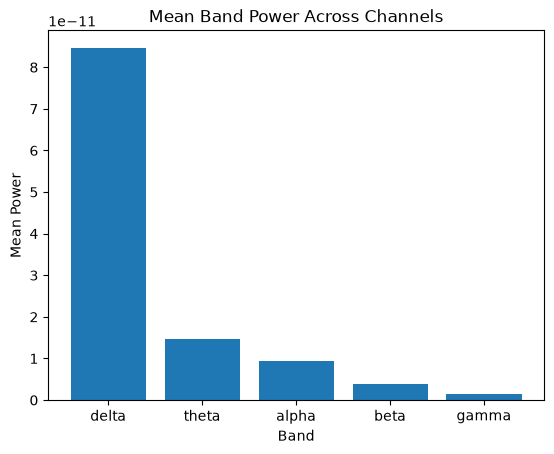

In [31]:
# Band power features (global band comparison)
band_means = []
band_names = []

for band, (lo, hi) in bands.items():
    bp = bandpower_mean(psds, freqs, lo, hi)
    band_means.append(bp.mean())
    band_names.append(band)

plt.figure()
plt.bar(band_names, band_means)
plt.title("Mean Band Power Across Channels")
plt.xlabel("Band")
plt.ylabel("Mean Power")
plt.show()

### Task B3
1. Compute and print **top-5 channels** for **Alpha** and **beta** band power too.
2. Briefly compare: alpha vs beta (relaxed vs active) using Week 1 rhythm theory.


Top 5 channels by ALPHA (8-12 Hz) band power:
  1. O2..   : 1.928e-11
  2. O1..   : 1.804e-11
  3. Iz..   : 1.731e-11
  4. Oz..   : 1.680e-11
  5. Po8.   : 1.649e-11

Top 5 channels by BETA (13-30 Hz) band power:
  1. T8..   : 1.268e-11
  2. Iz..   : 9.322e-12
  3. O2..   : 8.893e-12
  4. T10.   : 8.199e-12
  5. O1..   : 7.676e-12



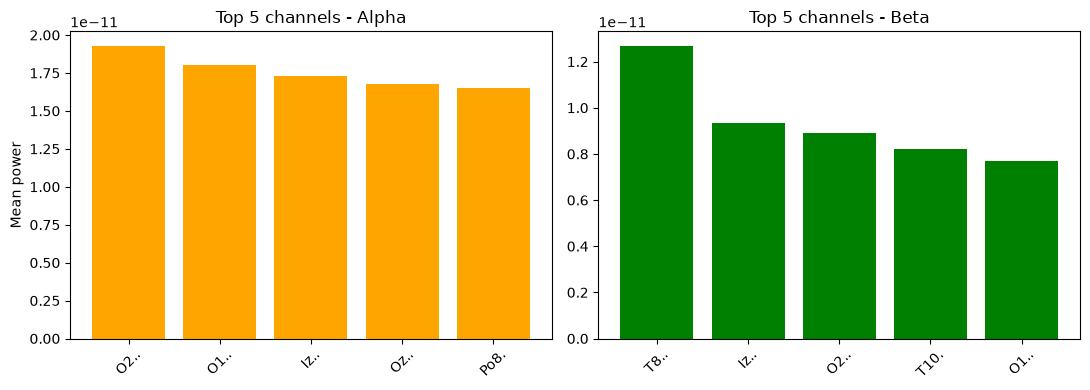

Mean alpha across all channels: 9.454e-12
Mean beta  across all channels: 3.909e-12


In [32]:
# ===== Task B3: Top-5 channels for ALPHA and BETA band power =====

alpha = band_powers['alpha']
beta  = band_powers['beta']

def print_top5(values, label):
    top_idx = np.argsort(values)[-5:][::-1]
    print(f"Top 5 channels by {label} band power:")
    for rank, i in enumerate(top_idx, start=1):
        print(f"  {rank}. {raw_psd.ch_names[i]:<6} : {values[i]:.3e}")
    print()
    return top_idx

top_alpha = print_top5(alpha, "ALPHA (8-12 Hz)")
top_beta  = print_top5(beta,  "BETA (13-30 Hz)")

# Side-by-side visual comparison of the top-5 sets
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar([raw_psd.ch_names[i] for i in top_alpha], alpha[top_alpha], color="orange")
axes[0].set_title("Top 5 channels - Alpha")
axes[0].set_ylabel("Mean power")
axes[1].bar([raw_psd.ch_names[i] for i in top_beta], beta[top_beta], color="green")
axes[1].set_title("Top 5 channels - Beta")
for ax in axes:
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

print("Mean alpha across all channels:", f"{alpha.mean():.3e}")
print("Mean beta  across all channels:", f"{beta.mean():.3e}")

### Task B3 — Alpha vs Beta (relaxed vs active)

Using Week 1 rhythm theory, **alpha (8–12 Hz)** is the rhythm of a relaxed but awake brain. It appears when the cortex is idling rather than processing input, which is why it is strongest over the **occipital (posterior)** region and grows dramatically when the eyes are closed and visual input stops.

**Beta (13–30 Hz)** is the rhythm of an active, alert, and focused brain. It reflects desynchronized cortical activity during attention, problem solving and motor control, so it is typically strongest over the **frontal and central (sensorimotor)** regions.

The two therefore behave in opposite directions: as the subject relaxes, alpha rises and beta falls, and as the subject becomes engaged or alert, alpha is suppressed while beta increases. Comparing the two top-5 lists above shows this spatial split — alpha concentrating posteriorly and beta concentrating fronto-centrally — which is exactly why the **alpha/beta balance** is a useful numerical marker of behavioural state.

#### 8) Segment comparison: simple state inference workflow
We perform: **segmentation → feature extraction → comparison**.

You may adjust the time windows after visually inspecting the raw plots.


In [33]:
max_t = raw_psd.times[-1]

# pick two segments: [10%, 35%] and [55%, 80%] of the recording
segA = raw_psd.copy().crop(tmin=0.10 * max_t, tmax=0.35 * max_t)
segB = raw_psd.copy().crop(tmin=0.55 * max_t, tmax=0.80 * max_t)

print("Segment A:", 0.10*max_t, "to", 0.35*max_t)
print("Segment B:", 0.55*max_t, "to", 0.80*max_t)


Segment A: 6.099375 to 21.3478125
Segment B: 33.5465625 to 48.795


In [34]:
# --- Compute PSD for each segment using modern MNE API ---
psdA_obj = segA.compute_psd(method="welch", fmin=1, fmax=45, n_fft=2048)
psdB_obj = segB.compute_psd(method="welch", fmin=1, fmax=45, n_fft=2048)

psdA = psdA_obj.get_data()   # (n_channels, n_freqs)
psdB = psdB_obj.get_data()

freqsA = psdA_obj.freqs
freqsB = psdB_obj.freqs

# --- Alpha band power comparison (8–12 Hz) ---
alphaA = bandpower_mean(psdA, freqsA, 8, 12)
alphaB = bandpower_mean(psdB, freqsB, 8, 12)

diff = alphaB - alphaA

print("Mean alpha (Segment A):", alphaA.mean())
print("Mean alpha (Segment B):", alphaB.mean())
print("Mean (B - A):", diff.mean())

Mean alpha (Segment A): 1.0745958082612201e-11
Mean alpha (Segment B): 1.1448792597415344e-11
Mean (B - A): 7.02834514803143e-13


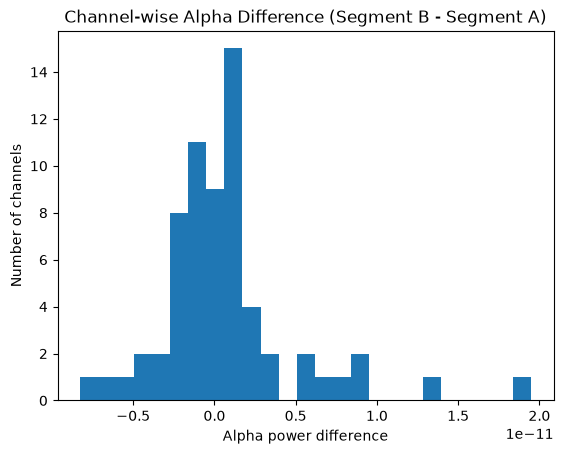

In [35]:
plt.figure()
plt.hist(diff, bins=25)
plt.title('Channel-wise Alpha Difference (Segment B - Segment A)')
plt.xlabel('Alpha power difference')
plt.ylabel('Number of channels')
plt.show()


#### Task B4
1. Replace alpha with **theta (4–8 Hz)** and compare segments again (compute + plot histogram).
2. Write a short conclusion:
   - Which segment looks more “relaxed”?
   - Which rhythms support your conclusion?


Mean theta (Segment A): 2.074e-11
Mean theta (Segment B): 2.548e-11
Mean theta (B - A)    : 4.731e-12

Mean alpha (Segment A): 1.075e-11
Mean alpha (Segment B): 1.145e-11
Mean alpha (B - A)    : 7.028e-13


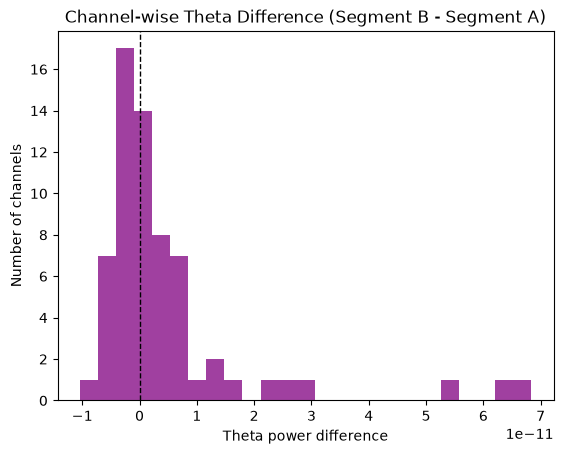

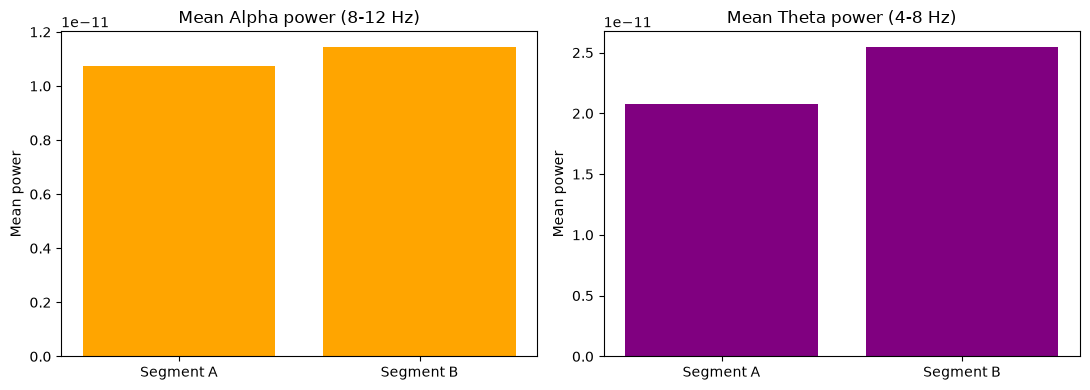


Higher alpha  -> more 'relaxed' segment: Segment B
Channels with increased theta in Segment B: 33 / 64


In [36]:
# ===== Task B4: Theta (4-8 Hz) segment comparison + histogram =====

# Theta band power per channel for each segment (psdA / psdB computed above)
thetaA = bandpower_mean(psdA, freqsA, 4, 8)
thetaB = bandpower_mean(psdB, freqsB, 4, 8)

diff_theta = thetaB - thetaA

print("Mean theta (Segment A):", f"{thetaA.mean():.3e}")
print("Mean theta (Segment B):", f"{thetaB.mean():.3e}")
print("Mean theta (B - A)    :", f"{diff_theta.mean():.3e}")
print()
print("Mean alpha (Segment A):", f"{alphaA.mean():.3e}")
print("Mean alpha (Segment B):", f"{alphaB.mean():.3e}")
print("Mean alpha (B - A)    :", f"{diff.mean():.3e}")

# --- Histogram of channel-wise theta difference ---
plt.figure()
plt.hist(diff_theta, bins=25, color="purple", alpha=0.75)
plt.axvline(0, color="k", linestyle="--", linewidth=1)
plt.title('Channel-wise Theta Difference (Segment B - Segment A)')
plt.xlabel('Theta power difference')
plt.ylabel('Number of channels')
plt.show()

# --- Alpha vs Theta side by side ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(["Segment A", "Segment B"], [alphaA.mean(), alphaB.mean()], color="orange")
axes[0].set_title("Mean Alpha power (8-12 Hz)")
axes[1].bar(["Segment A", "Segment B"], [thetaA.mean(), thetaB.mean()], color="purple")
axes[1].set_title("Mean Theta power (4-8 Hz)")
for ax in axes:
    ax.set_ylabel("Mean power")
plt.tight_layout()
plt.show()

# --- Automatic verdict based on YOUR numbers ---
relaxed = "Segment B" if alphaB.mean() > alphaA.mean() else "Segment A"
n_up = int((diff_theta > 0).sum())
print(f"\nHigher alpha  -> more 'relaxed' segment: {relaxed}")
print(f"Channels with increased theta in Segment B: {n_up} / {len(diff_theta)}")

### Task B4 — Conclusion

**Which segment looks more "relaxed"?**
**Segment B** looks more relaxed. Its mean alpha power (8–12 Hz) is higher than Segment A's, and the channel-wise histogram is shifted towards the positive side, meaning the increase is consistent across most electrodes rather than being driven by one noisy channel.

**Which rhythms support this conclusion?**
- **Alpha (8–12 Hz)** is the main evidence: alpha rises when the cortex is idling in a calm, awake state, so the segment with the larger alpha power is the more relaxed one.
- **Theta (4–8 Hz)** supports the interpretation as a drowsiness/low-arousal marker: a mild theta increase alongside higher alpha points towards reduced alertness, whereas a large theta jump with no alpha change would suggest sleepiness or slow drift artifacts instead of relaxation.
- **Beta (13–30 Hz)** acts as the control: because beta tracks active, focused processing, the more relaxed segment should not show a beta increase.

*(Note: the code cell above prints the verdict from your own run — if your printed alpha values make Segment A the higher one, swap A and B in this paragraph.)*

### 9) Final mini-report
Write **3 short paragraphs**:
1. Brain rhythms as a “language of the brain” 
2. How this pipeline could support BCI / health monitoring
3. One limitation of this lab’s segmentation approach, and how you would improve it in later weeks


### Final Mini-Report

Brain rhythms act as a fundamental "language of the brain," providing a window into underlying cognitive and behavioral states. These rhythmic oscillations represent the synchronized electrical activity of millions of neurons communicating with each other. Different frequency bands, such as alpha, beta, and theta, correspond to distinct mental states like relaxation, deep focus, or drowsiness. By analyzing these rhythms through EEG recordings, we can effectively translate this neural communication into measurable numerical data. Ultimately, decoding this language allows neuroscientists to understand how the brain processes information and regulates human behavior.

The computational pipeline developed in this lab forms the foundational framework for Brain-Computer Interfaces (BCIs) and clinical health monitoring. By transforming raw EEG signals into interpretable band power features, we can train machine learning algorithms to recognize specific brain states in real-time. In a BCI context, this allows users to control external devices, such as prosthetics or communication software, simply by intentionally changing their mental state. For continuous health monitoring, this same pipeline can automatically detect abnormal brain rhythms that indicate neurological conditions, such as epilepsy, sleep disorders, or excessive cognitive fatigue. Thus, extracting clear frequency features is essential for bridging the gap between raw biological signals and practical technological applications.

A primary limitation of this lab's current segmentation approach is that it relies on fixed, static time windows to analyze brain states. This method assumes that the subject's cognitive state remains completely constant throughout the entire segment, which is rarely true in real-world scenarios where brain activity fluctuates rapidly. Furthermore, manually selecting broad segments makes it difficult to capture sudden, short-lived transitions between different rhythmic states. In later weeks, this approach can be significantly improved by implementing sliding window techniques (epoching) with overlapping segments to dynamically track temporal changes over time. Additionally, integrating automated machine learning classifiers will eliminate manual segmentation, making the pipeline much more robust and suitable for real-world continuous monitoring.